# 멀티모달 RAG 실습 — 교보증권 투자설명서

PDF 한 편의 **텍스트 · 표 · 이미지**를 모두 검색 대상으로 삼아 질문에 답하는 멀티모달 RAG를 처음부터 끝까지 실행합니다.
함수는 `src/`에 있고, 이 노트북은 **실행 순서**만 담당합니다.

```
[PDF] ─① 파싱(src/extract.py)──▶ 텍스트 / 표 / 이미지
      ─② 요약(src/summarize.py)─▶ 텍스트·표: LLM 요약 / 이미지: VLM 요약
      ─③ 저장(src/retriever.py)─▶ 요약 → Chroma(검색용) / 원본 → docstore(답변용), doc_id로 연결
      ─④ 답변(src/retriever.py)─▶ 질문 → 요약으로 검색 → 원본 이미지·텍스트 → gpt-4o-mini → 답변
```

**핵심: "검색은 요약으로, 답변은 원본으로"**

## 0. 환경 확인

In [1]:
import logging
import os
import sys
import warnings
from pathlib import Path

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT))  # src 폴더를 import 할 수 있도록

# 라이브러리 경고·안내 문구 정리
warnings.filterwarnings("ignore")
logging.getLogger("pdfminer").setLevel(logging.ERROR)
os.environ["UNSTRUCTURED_DISABLE_NOTICE"] = "1"

from src.extract import ensure_os_tools

print("Python:", sys.version.split()[0])
print("가상환경 안에서 실행 중?", ".venv" in sys.prefix)
tools = ensure_os_tools()  # Poppler·Tesseract가 PATH에 없으면 기본 설치 경로 보정
print("Poppler  :", "OK" if tools["poppler"] else "✗ 미설치")
print("Tesseract:", "OK" if tools["tesseract"] else "✗ 미설치")
for mod in ["langchain", "langchain_classic", "unstructured", "chromadb", "tiktoken", "PIL"]:
    try:
        __import__(mod)
        print(f"{mod:18s}: OK")
    except ImportError:
        print(f"{mod:18s}: ✗ 미설치")

Python: 3.11.9
가상환경 안에서 실행 중? True
Poppler  : OK
Tesseract: OK
langchain         : OK
langchain_classic : OK
unstructured      : OK


chromadb          : OK
tiktoken          : OK
PIL               : OK


## 1. 설정 — API 키, 경로, 모델

In [2]:
from dotenv import load_dotenv

from src.retriever import ANSWER_MODEL, EMBEDDING_MODEL
from src.summarize import LLM_MODEL, VLM_MODEL

load_dotenv(ROOT / ".env")
assert os.getenv("OPENAI_API_KEY", "").startswith("sk-"), ".env 파일의 OPENAI_API_KEY를 확인하세요."
print("API 키 로딩 완료")  # 키 값은 출력하지 않음

DATA_DIR = ROOT / "data"
PDF_PATH = DATA_DIR / "[교보증권]투자설명서(일괄신고)(2026.11.04).pdf"
FIGURES_DIR = DATA_DIR / "figures"                # 추출 이미지 (Git 제외)
PROCESSED_DIR = DATA_DIR / "processed" / "kyobo"  # 중간 결과 pickle (Git 제외)

REPARSE = False  # True면 저장된 파싱 결과가 있어도 PDF를 다시 파싱 (2~3분)

print("PDF 존재 여부:", PDF_PATH.exists())
print(f"모델 — 텍스트요약 {LLM_MODEL} / 이미지요약 {VLM_MODEL} / 답변 {ANSWER_MODEL} / 임베딩 {EMBEDDING_MODEL}")

API 키 로딩 완료
PDF 존재 여부: True
모델 — 텍스트요약 gpt-4o-mini / 이미지요약 gpt-4o-mini / 답변 gpt-4o-mini / 임베딩 text-embedding-3-small


## 2. ① PDF 파싱 → 분류 → 재분할

- `partition_pdf(strategy="hi_res")`: 레이아웃 모델이 페이지를 보고 제목·본문·표·그림을 구분합니다.
- `chunking_strategy="by_title"`: 제목 단위로 묶은 텍스트 덩어리가 **CompositeElement**가 됩니다.
- 그림은 이 단계에서 `data/figures/figure-{페이지}-{순번}.jpg` 로 저장됩니다.
- 파싱은 2~3분 걸리므로 결과를 `extracted.pkl`로 저장해 두고 다시 실행할 때는 불러옵니다.

In [3]:
import pickle
import time
from collections import Counter

from src.extract import categorize_elements, extract_pdf_elements, split_texts

extracted_pkl = PROCESSED_DIR / "extracted.pkl"

if extracted_pkl.exists() and not REPARSE:
    with open(extracted_pkl, "rb") as f:
        extracted = pickle.load(f)
    print("저장된 파싱 결과 사용:", extracted_pkl.relative_to(ROOT))
else:
    for old in FIGURES_DIR.glob("figure-*.jpg"):  # 이전 실행 이미지 정리
        old.unlink()
    start = time.time()
    raw_pdf_elements = extract_pdf_elements(PDF_PATH, image_dir=FIGURES_DIR, languages=("kor", "eng"))
    print(f"파싱 시간: {time.time() - start:.0f}초")

    texts, tables = categorize_elements(raw_pdf_elements)
    texts_2k_token = split_texts(texts, chunk_size=2000, chunk_overlap=200)
    extracted = {
        "type_counts": dict(Counter(type(e).__name__ for e in raw_pdf_elements).most_common()),
        "texts": texts,
        "tables": tables,
        "texts_2k_token": texts_2k_token,
    }
    PROCESSED_DIR.mkdir(parents=True, exist_ok=True)
    with open(extracted_pkl, "wb") as f:
        pickle.dump(extracted, f)
    print("저장:", extracted_pkl.relative_to(ROOT))

texts, tables, texts_2k_token = extracted["texts"], extracted["tables"], extracted["texts_2k_token"]
print("요소 종류:", extracted["type_counts"])
print(f"텍스트 블록 {len(texts)}개 → 재분할 {len(texts_2k_token)}개 | 표 {len(tables)}개")

저장된 파싱 결과 사용: data\processed\kyobo\extracted.pkl
요소 종류: {'CompositeElement': 39, 'Table': 35}
텍스트 블록 39개 → 재분할 27개 | 표 35개


In [4]:
print("[재분할 텍스트 0] 앞 300자\n", texts_2k_token[0][:300])
print("\n[표 0] 앞 300자\n", tables[0][:300])

[재분할 텍스트 0] 앞 300자
 목 차 투 자 설 명 서

2026년 11월 04일

교보증권 주식회사

교보증권 제12879회 주가연계파생결합사채

금 13,329,540,000 원

1. 증권신고의 효력발생일 :

2026년 11월 04일

2. 모집가액 :

금 13,329,540,000원

3. 청약기간 : 2026년 11월 12일

4. 납입기일 :

2026년 11월 12일

5. 증권신고서 및 투자설명서의 열람장소

가. 증권신고서 : 금융위(금감원) 전자공시시스템 → http://dart.fss.or.kr 나. 일괄신고 추가서류 : 금융위(금감원) 

[표 0] 앞 300자
 투 자 설 명 서 ............................................................................................................................................1 【 본 문 】 ............................................................................................................................................


### 추출된 이미지 확인

8KB 미만 이미지는 아이콘·기호 조각이라 요약 대상에서 뺍니다.

추출 이미지 6장 / 8KB 이상(요약 대상) 6장
  figure-13-2.jpg       106 KB
  figure-13-3.jpg       198 KB
  figure-14-4.jpg       104 KB
  figure-18-5.jpg        54 KB
  figure-34-6.jpg        96 KB
  figure-6-1.jpg         14 KB


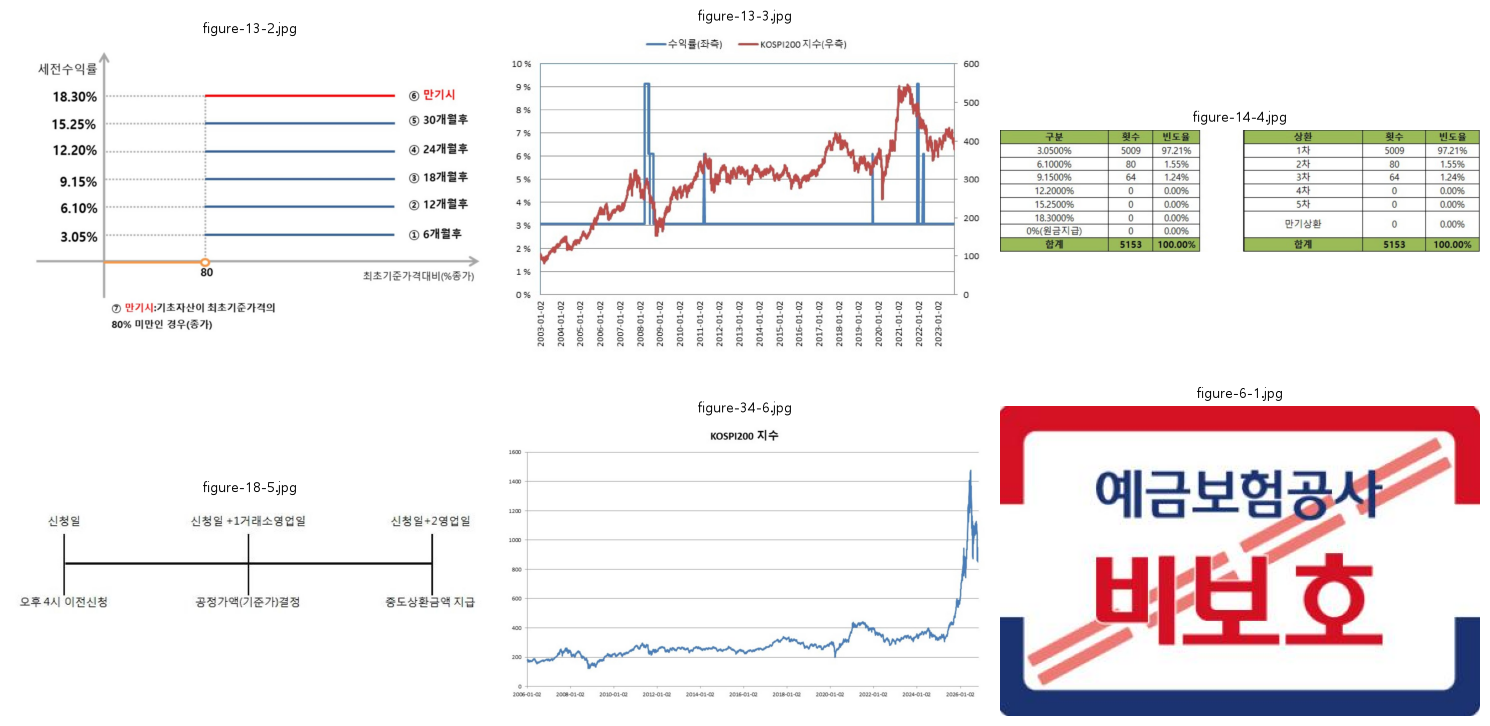

In [5]:
import matplotlib.pyplot as plt
from PIL import Image

plt.rcParams["font.family"] = "Malgun Gothic"

MIN_KB = 8
figs = sorted(FIGURES_DIR.glob("figure-*.jpg"))
big = [f for f in figs if f.stat().st_size >= MIN_KB * 1024]
print(f"추출 이미지 {len(figs)}장 / {MIN_KB}KB 이상(요약 대상) {len(big)}장")
for f in figs:
    print(f"  {f.name:20s} {f.stat().st_size // 1024:4d} KB")

cols = 3
rows = (len(big) + cols - 1) // cols
fig, axes = plt.subplots(rows, cols, figsize=(15, 4 * rows), squeeze=False)
for ax in axes.flat:
    ax.axis("off")
for ax, f in zip(axes.flat, big):
    ax.imshow(Image.open(f))
    ax.set_title(f.name, fontsize=10)
plt.tight_layout()
plt.show()

## 3. ② 요약 생성

### 텍스트·표 요약 (LLM)

`{"element": lambda x: x} | prompt | model | StrOutputParser()` 체인을 `batch(max_concurrency=5)`로 실행합니다.
같은 입력은 `data/cache/`에 저장된 결과를 재사용해 API를 다시 호출하지 않습니다.

In [6]:
from src.summarize import generate_text_summaries

text_summaries, table_summaries = generate_text_summaries(texts_2k_token, tables, summarize_texts=True)
print(f"텍스트 요약 {len(text_summaries)}개 | 표 요약 {len(table_summaries)}개")
print("\n[text_summaries[0]]\n", text_summaries[0])
print("\n[table_summaries[0]]\n", table_summaries[0])

텍스트 요약 27개 | 표 요약 35개

[text_summaries[0]]
 **투자설명서 요약**

- **발행일**: 2026년 11월 04일
- **발행기관**: 교보증권 주식회사
- **상품명**: 교보증권 제12879회 주가연계파생결합사채
- **모집가액**: 13,329,540,000원
- **청약기간**: 2026년 11월 12일
- **납입기일**: 2026년 11월 12일
- **열람장소**: 금융위 전자공시시스템 (http://dart.fss.or.kr) 및 교보증권 본·지점
- **안정조작/시장조성**: 해당사항 없음
- **유의사항**: 투자원금 손실 가능성, 예금자 보호대상 아님. 투자판단 시 관련 서류 참고 필요.

[table_summaries[0]]
 투자 설명서의 주요 내용은 다음과 같습니다: 문서의 첫 부분은 투자 관련 정보와 지침을 제공하며, 전체 문서는 1페이지에 걸쳐 있습니다. 본 문은 2페이지에 위치하고 있습니다.


### 이미지 요약 (VLM)

이미지를 Base64로 인코딩해 gpt-4o-mini에 보내고 **검색용 요약**을 받습니다.
이 요약이 질문과 매칭되어야 이미지가 검색되므로, 프롬프트에서 **표는 모든 행을, 그래프는 모든 수치를 옮겨 적도록** 지시합니다.
(처음에 "간결하게 요약"하도록 했을 때는 `figure-14-4`의 '1차~5차 조기상환' 표가 요약에서 빠져 이미지가 검색되지 않았습니다.)

In [7]:
from src.summarize import generate_img_summaries

img_base64_list, image_summaries, img_files = generate_img_summaries(str(FIGURES_DIR), min_kb=MIN_KB)
print(f"이미지 요약 {len(image_summaries)}개\n")
for name, summary in zip(img_files, image_summaries):
    print(f"■ {name}\n{summary}\n")

이미지 요약 6개

■ figure-13-2.jpg
주제: 세전수익률

- 세전수익률:
  - 만기시: 18.30%
  - 30개월 후: 15.25%
  - 24개월 후: 12.20%
  - 18개월 후: 9.15%
  - 12개월 후: 6.10%
  - 6개월 후: 3.05%

- 기준선: 최소기준가격비(%)는 80에 해당.

검색 키워드: 세전수익률, 만기, 최소기준가격, 투자, 금융

■ figure-13-3.jpg
주제: 수익률(좌측)

- 수익률(좌측): 0%, 1%, 2%, 3%, 4%, 5%, 6%, 7%, 8%, 9%, 10%
- KOSPI200 지수(우측): 0, 100, 200, 300, 400, 500, 600

차트의 주요 포인트:
- 2003년 1월 2일: 수익률 2%, KOSPI200 지수 200
- 2007년 1월 2일: 수익률 6%, KOSPI200 지수 400
- 2009년 1월 2일: 수익률 9%, KOSPI200 지수 500
- 2010년 1월 2일: 수익률 5%, KOSPI200 지수 300
- 2020년 1월 2일: 수익률 7%, KOSPI200 지수 450
- 2023년 1월 2일: 수익률 4%, KOSPI200 지수 400

검색 키워드: 수익률, KOSPI200, 차트, 금융, 경제, 투자, 데이터, 분석

■ figure-14-4.jpg
주제: 구분 및 상환

구분:
- 3.0500%: 5009, 97.21%
- 6.1000%: 80, 1.55%
- 9.1500%: 64, 1.24%
- 12.2000%: 0, 0.00%
- 15.2500%: 0, 0.00%
- 18.3000%: 0, 0.00%
- 0% (원금지급): 0, 0.00%
- 합계: 5153, 100.00%

상환:
- 1차: 5009, 97.21%
- 2차: 80, 1.55%
- 3차: 64, 1.24%
- 4차: 0, 0.00%
- 5차: 0, 0.00%
- 만기상환: 0, 0.00%
- 합계: 5153, 100.00%

검색 키워드: 구분, 상환, 비

### 요약 결과 저장

In [8]:
summaries = {
    "text_summaries": text_summaries,
    "table_summaries": table_summaries,
    "image_summaries": image_summaries,
    "img_files": img_files,
    "img_base64_list": img_base64_list,  # 원본 이미지 (Base64)
}
with open(PROCESSED_DIR / "summaries.pkl", "wb") as f:
    pickle.dump(summaries, f)
print("저장:", (PROCESSED_DIR / "summaries.pkl").relative_to(ROOT))

저장: data\processed\kyobo\summaries.pkl


## 4. ③ 다중 벡터 검색기 (MultiVectorRetriever)

| 저장소 | 들어가는 것 | 용도 |
| --- | --- | --- |
| Chroma (벡터DB) | 요약 + 요약 임베딩 | 검색 |
| InMemoryStore (docstore) | 원본 텍스트·표·이미지(Base64) | 답변 근거 |
| `doc_id` (uuid) | 요약 ↔ 원본 연결 고리 | |

In [9]:
from src.retriever import add_documents, create_multi_vector_retriever

retriever = create_multi_vector_retriever(k=4)
add_documents(retriever, text_summaries, texts_2k_token, "text")
add_documents(retriever, table_summaries, tables, "table")
add_documents(retriever, image_summaries, img_base64_list, "image")

print("벡터DB 요약 수 :", retriever.vectorstore._collection.count())
print("docstore 원본 수:", len(list(retriever.docstore.yield_keys())))

벡터DB 요약 수 : 68
docstore 원본 수: 68


### 검색 확인 — 이미지에만 있는 정보를 물으면 이미지 원본이 돌아오는가?

In [10]:
from src.retriever import matched_types, split_image_text_types

q = "모의실험 결과에서 1차 조기상환 빈도율과 횟수는 얼마인가요?"
docs = split_image_text_types(retriever.invoke(q))
print("매칭된 요약 종류:", matched_types(retriever, q))
print(f"반환된 원본 → 이미지 {len(docs['images'])}장, 텍스트/표 {len(docs['texts'])}개")
print("이미지 원본 앞 60자:", docs["images"][0][:60] if docs["images"] else "-")

매칭된 요약 종류: ['text', 'table', 'image', 'table']
반환된 원본 → 이미지 1장, 텍스트/표 3개
이미지 원본 앞 60자: /9j/4AAQSkZJRgABAQAAAQABAAD/2wBDAAgGBgcGBQgHBwcJCQgKDBQNDAsL


## 5. ④ 질의응답 — 텍스트 전용 RAG(Before) vs 멀티모달 RAG(After)

두 체인은 **같은 모델(gpt-4o-mini)·같은 지시문**을 쓰고, 검색 대상만 다릅니다.
- Before: 텍스트 청크(`texts_2k_token`)만 임베딩해서 검색
- After : 텍스트·표·이미지 요약으로 검색하고 원본을 돌려받음

질문 1~4는 답이 **이미지(모의실험 빈도표, 수익구조 그래프)에만** 있고, 5~6은 본문에도 있는 대조용 질문입니다.

In [11]:
from src.retriever import build_rag_chain, create_text_only_retriever

chain = build_rag_chain(retriever, lang="ko")
text_only_chain = build_rag_chain(create_text_only_retriever(texts_2k_token, k=4), lang="ko")

QUESTIONS = [
    "모의실험 결과에서 1차 조기상환 빈도율과 횟수는 얼마인가요?",
    "모의실험에서 2차, 3차 조기상환은 각각 몇 회, 몇 %였나요?",
    "모의실험 결과 원금만 지급(0%)된 경우는 몇 번이었나요?",
    "18개월 후에 조기상환되면 세전 수익률은 몇 %인가요?",
    "만기평가가격이 최초기준가격의 80% 이상이면 만기에 얼마를 받나요?",
    "중도상환을 신청하면 중도상환금은 언제 지급되나요?",
]

results = []
for q in QUESTIONS:
    r = {
        "question": q,
        "sources": matched_types(retriever, q),
        "text_only": text_only_chain.invoke(q),
        "multimodal": chain.invoke(q),
    }
    results.append(r)
    print(f"Q. {q}\n근거 원본 종류: {r['sources']}")
    print(f"[Before · 텍스트 전용]\n{r['text_only']}")
    print(f"[After · 멀티모달]\n{r['multimodal']}\n" + "-" * 80)

Q. 모의실험 결과에서 1차 조기상환 빈도율과 횟수는 얼마인가요?
근거 원본 종류: ['text', 'table', 'image', 'table']
[Before · 텍스트 전용]
모의실험 결과에서 1차 조기상환 빈도율과 횟수에 대한 구체적인 수치는 자료에 포함되어 있지 않습니다. 따라서 해당 정보를 제공할 수 없습니다.
[After · 멀티모달]
모의실험 결과에서 1차 조기상환의 빈도율은 97.21%이며, 횟수는 5009회입니다.
--------------------------------------------------------------------------------


Q. 모의실험에서 2차, 3차 조기상환은 각각 몇 회, 몇 %였나요?
근거 원본 종류: ['table', 'table', 'table', 'image']
[Before · 텍스트 전용]
모의실험에서 2차 조기상환은 6회, 30%였고, 3차 조기상환은 0회, 0%였습니다.
[After · 멀티모달]
모의실험에서 2차 조기상환은 80회, 1.55%였고, 3차 조기상환은 64회, 1.24%였습니다.
--------------------------------------------------------------------------------


Q. 모의실험 결과 원금만 지급(0%)된 경우는 몇 번이었나요?
근거 원본 종류: ['table', 'text', 'table', 'text']
[Before · 텍스트 전용]
모의실험 결과 원금만 지급(0%)된 경우는 총 6번이었습니다.
[After · 멀티모달]
모의실험 결과 원금만 지급(0%)된 경우는 총 3번이었습니다.
--------------------------------------------------------------------------------


Q. 18개월 후에 조기상환되면 세전 수익률은 몇 %인가요?
근거 원본 종류: ['image', 'text', 'table', 'table']
[Before · 텍스트 전용]
18개월 후에 조기상환되면 세전 수익률은 18.30%입니다.
[After · 멀티모달]
18개월 후에 조기상환되면 세전 수익률은 9.15%입니다.
--------------------------------------------------------------------------------


Q. 만기평가가격이 최초기준가격의 80% 이상이면 만기에 얼마를 받나요?
근거 원본 종류: ['table', 'table', 'table', 'image']
[Before · 텍스트 전용]
만기평가가격이 최초기준가격의 80% 이상인 경우, 만기일에 지급받는 상환금액은 최초기준가격과 동일합니다. 구체적으로, 만기상환금액 결정조건에 따라 만기평가가격이 최초기준가격의 80% 이상일 경우, 상환금액은 최초기준가격으로 지급됩니다.
[After · 멀티모달]
만기평가가격이 최초기준가격의 80% 이상인 경우, 만기에 받는 금액은 액면금액의 118.30%입니다.
--------------------------------------------------------------------------------


Q. 중도상환을 신청하면 중도상환금은 언제 지급되나요?
근거 원본 종류: ['table', 'image', 'table', 'table']
[Before · 텍스트 전용]
중도상환을 신청하면 중도상환금은 해당 차수의 평가일(불포함) 후 2영업일에 지급됩니다. 즉, 중도상환이 이루어진 경우, 상환금액은 중도상환 평가일 이후 2영업일에 투자자의 계좌로 현금으로 지급됩니다.
[After · 멀티모달]
중도상환을 신청하면 중도상환금은 중도상환 신청일(불포함) 이후 2영업일에 해당하는 날에 지급됩니다.
--------------------------------------------------------------------------------


In [12]:
import json

out = PROCESSED_DIR / "qa_results.json"
out.write_text(json.dumps(results, ensure_ascii=False, indent=2), encoding="utf-8")
print("결과 저장:", out.relative_to(ROOT))

결과 저장: data\processed\kyobo\qa_results.json


## 6. ⑤ (선택) 번역 체인 — 영어 답변 → 로컬 LLM(Ollama) 한국어 번역

멀티모달 체인 뒤에 로컬 모델을 이어 붙여 후처리합니다. Ollama가 꺼져 있으면 건너뜁니다.

In [13]:
import requests
from langchain_core.output_parsers import StrOutputParser
from langchain_core.prompts import ChatPromptTemplate
from langchain_core.runnables import RunnablePassthrough

try:
    ollama_on = requests.get("http://localhost:11434", timeout=1).ok
except requests.RequestException:
    ollama_on = False

if ollama_on:
    from langchain_ollama.llms import OllamaLLM

    translate_prompt = ChatPromptTemplate.from_template(
        "다음 영문 답변을 자연스러운 한국어로 번역하세요. 숫자와 고유명사는 그대로 두세요. "
        "번역문만 출력하세요.\n\n{answer}"
    )
    english_chain = build_rag_chain(retriever, lang="en")
    final_chain = (
        english_chain
        | {"answer": RunnablePassthrough()}
        | translate_prompt
        | OllamaLLM(model="llama3.1:8b", temperature=0)
        | StrOutputParser()
    )
    q = QUESTIONS[0]
    print("Q.", q)
    print("[영문 답변]\n", english_chain.invoke(q))
    print("\n[Ollama 한국어 번역]\n", final_chain.invoke(q))
else:
    print("Ollama가 실행 중이 아니라 번역 체인을 건너뜁니다. (ollama serve / ollama pull llama3.1:8b)")

Q. 모의실험 결과에서 1차 조기상환 빈도율과 횟수는 얼마인가요?


[영문 답변]
 The frequency rate and count for the 1st early redemption are as follows:

- **Count**: 5009
- **Frequency Rate**: 97.21% 

These numbers are taken from the provided table.



[Ollama 한국어 번역]
 1차 조기상환의 빈도율과 카운트는 다음과 같습니다.

- 빈도율: 97.21%
- 카운트: 5009


## ✅ 체크포인트

- [ ] `data/figures/`에 추출 이미지가 있고, 요약 대상 이미지를 눈으로 확인했다
- [ ] `data/processed/kyobo/`에 `extracted.pkl`, `summaries.pkl`이 생성되었다
- [ ] 이미지에만 있는 정보를 묻는 질문에서 멀티모달 RAG가 이미지 원본을 근거로 답했다
- [ ] `data/processed/kyobo/qa_results.json`에 Before/After 결과가 저장되었다